[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JPEDROPS092/machine-learning-algorithms/blob/main/notebooks/10-plantas-amazonia-regressao-logistica.ipynb)

# Arvores da Amazonia Central com regressao logistica

Dado real, nao sintetico: censo de arvores em parcelas de adubacao na Amazonia Central, Cunha et al. 2021, NERC Environmental Information Data Centre, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. O CSV nao informa qual parcela recebeu qual adubo; esse rotulo nao e inventado.

Nao ha, neste caderno, um conjunto famoso de "plantas da Amazonia" de tutorial. O arquivo usado e o censo florestal publico de Cunha, Quesada, Di Ponzio, Lopes, Deambrozi, Brum, Andersen e Hartley (2021): diametro a altura do peito (DAP, em cm) medido em 2017, 2018 e 2019, familia botanica e parcela, em blocos de terra firme na Amazonia Central. Licenca Open Government Licence v3. O zip tem cerca de meio megabyte e baixa sem cadastro.

O CSV nao traz o codigo do tratamento experimental. Por isso a pergunta nao e "esta parcela foi adubada?". A pergunta que as colunas sustentam e outra: com o DAP de 2017 e o incremento ate 2019, da para separar palmeiras (`Arecaceae`) de lecitidaceas (`Lecythidaceae`, o grupo das matamatas e afins)? As palmeiras deste censo, acima do limite de inclusao, sao arvores finas. As lecitidaceas incluem copa. O sinal, se existir, mora sobretudo no diametro, nao numa assinatura fina de especie. O caderno mede isso e nao empurra a conclusao alem dos numeros.

Classe positiva = `Arecaceae`. Classe negativa = `Lecythidaceae`. Arvores sem os dois DAPs saem da tabela, e a contagem e impressa.


In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q numpy pandas scikit-learn matplotlib seaborn requests
    import os
    if not os.path.isdir("/content/ml-algoritmos/src/mlalgos"):
        !git clone --depth 1 https://github.com/JPEDROPS092/machine-learning-algorithms.git /content/ml-algoritmos
    if "/content/ml-algoritmos/src" not in sys.path:
        sys.path.insert(0, "/content/ml-algoritmos/src")
    PASTA_DADOS = Path("/content/data")
else:
    aqui = Path.cwd().resolve()
    raiz = aqui if (aqui / "src" / "mlalgos").exists() else aqui.parent
    if not (raiz / "src" / "mlalgos").exists():
        raise RuntimeError(
            "Nao encontrei src/mlalgos. Abra o notebook na pasta notebooks ou na raiz do repositorio."
        )
    if str(raiz / "src") not in sys.path:
        sys.path.insert(0, str(raiz / "src"))
    PASTA_DADOS = raiz / "data"

PASTA_DADOS.mkdir(parents=True, exist_ok=True)

%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def baixar(url, destino):
    """Baixa um arquivo so se ele ainda nao estiver na pasta data, que nao entra no git."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    import requests

    resposta = requests.get(url, timeout=180, headers={"User-Agent": "ml-algoritmos-aula/1.0"})
    resposta.raise_for_status()
    destino.write_bytes(resposta.content)
    return destino


def padronizar(treino, teste):
    """Z-score com media e desvio do treino. O teste usa os mesmos numeros, sem vazar."""
    treino = np.asarray(treino, dtype=float)
    teste = np.asarray(teste, dtype=float)
    media = treino.mean(axis=0)
    desvio = treino.std(axis=0)
    desvio = np.where(desvio == 0, 1.0, desvio)
    return (treino - media) / desvio, (teste - media) / desvio, media, desvio


## 1) Intuição

Quem faz inventario na floresta mede o tronco e anota a familia. Palmeira e matamata nao se confundem de perto, mas a planilha deste exercicio so tem o numero do tronco e o quanto ele mudou em dois anos. E como tentar reconhecer a arvore por uma fita metrica. As vezes o calibre basta, porque um grupo nem chega a ficar grosso; as vezes nao basta, e o modelo devolve uma probabilidade timida.

Dado real, nao sintetico: censo de arvores em parcelas de adubacao na Amazonia Central, Cunha et al. 2021, NERC Environmental Information Data Centre, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. O CSV nao informa qual parcela recebeu qual adubo; esse rotulo nao e inventado.


## 2) Fundamentação matemática

A regressao logistica desenha um escore linear e o espreme numa probabilidade. O escore e

$$
z = w^{\top} x + b
$$

- $x$ e o vetor de atributos da amostra.
- $w$ e o vetor de pesos, um por atributo.
- $b$ e o vies, o escore quando todos os atributos valem zero.
- $z$ e o logaritmo da chance, o log-odds: $\log \frac{p}{1-p} = z$.

A sigmoide converte $z$ na probabilidade da classe positiva:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

- Se $z = 0$, $\sigma(z) = 0{,}5$.
- Se $z$ cresce, $\sigma(z)$ sobe em direcao a 1, sem nunca passar de 1.
- Se $z$ cai, $\sigma(z)$ desce em direcao a 0.
- A derivada $\sigma(z)\,(1-\sigma(z))$ e a que aparece no gradiente.

Com mais de duas classes, cada classe tem seu escore $z_k$ e a softmax divide as exponenciais:

$$
P(y = k \mid x) = \frac{e^{z_k}}{\sum_{c=1}^{K} e^{z_c}}
$$

- $z_k = w_k^{\top} x + b_k$ e o escore da classe $k$.
- $K$ e o numero de classes.
- O denominador faz as $K$ probabilidades somarem 1.
- Subtrair $\max_c z_c$ antes da exponencial nao muda o resultado e evita estouro numerico.

O treino minimiza a entropia cruzada, a surpresa media de ter previsto pouco a classe verdadeira, mais uma penalidade L2 so nos pesos:

$$
J(w, b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\Big] + \frac{\lambda}{2}\|w\|^2
$$

- $n$ e o numero de amostras de treino.
- $y_i$ vale 1 na classe positiva e 0 na negativa.
- $\hat{p}_i = \sigma(w^{\top} x_i + b)$.
- $\lambda$ e o argumento `l2` do codigo. O vies $b$ nao entra em $\|w\|^2$: deslocar a fronteira nao deve ser punido do mesmo jeito que um peso enorme.
- No caso multiclasse, $y_i \log \hat{p}_i$ vira o log da probabilidade da classe correta.

A descida de gradiente anda no sentido em que $J$ diminui. Para a perda media acima, com a classe positiva codificada como 1:

$$
\frac{\partial J}{\partial w} = \frac{1}{n} X^{\top}(\hat{p} - y) + \lambda w, \qquad \frac{\partial J}{\partial b} = \frac{1}{n}\sum_{i=1}^{n}(\hat{p}_i - y_i)
$$

- $\hat{p} - y$ e o erro de cada amostra. Positivo quando o modelo exagerou a classe 1.
- $X^{\top}(\hat{p}-y)/n$ aponta quais atributos empurraram esse erro.
- $\lambda w$ encolhe os pesos em direcao a zero.
- O passo e $w \leftarrow w - \eta \, \partial J/\partial w$, e $\eta$ e o `learning_rate`.

O `C` do scikit-learn penaliza a soma dos erros, nao a media. Com $C = 1$, o $\lambda$ equivalente nesta media e $1/n$. E o valor usado nos cadernos para a comparacao ser justa. O otimizador deles (lbfgs) nao e o nosso passo fixo, entao os pesos nao precisam coincidir casa decimal; a qualidade no teste e que precisa ficar perto.

Ha duas colunas, $x_1$ o DAP inicial e $x_2$ o incremento. A fronteira $\sigma(w_1 x_1 + w_2 x_2 + b) = 0{,}5$ e uma reta no plano do inventario. Como as palmeiras sao poucas, $b$ e os pesos tendem a deixar a probabilidade da classe positiva abaixo de 0,5 na maior parte do plano. A ROC-AUC ainda pode ser alta: ela pergunta se as palmeiras ficam, em geral, com escore maior que as lecitidaceas, nao se o limiar 0,5 as acerta.

Dado real, nao sintetico: censo de arvores em parcelas de adubacao na Amazonia Central, Cunha et al. 2021, NERC Environmental Information Data Centre, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. O CSV nao informa qual parcela recebeu qual adubo; esse rotulo nao e inventado.


## 3) Visualização

Dado real, nao sintetico: censo de arvores em parcelas de adubacao na Amazonia Central, Cunha et al. 2021, NERC Environmental Information Data Centre, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. O CSV nao informa qual parcela recebeu qual adubo; esse rotulo nao e inventado.


Dado real, nao sintetico: Cunha et al. 2021, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. Tratamento da parcela ausente no arquivo; nao foi imputado.


arvores com os dois DAPs 4606
familia
Lecythidaceae    680
Arecaceae         84
Name: count, dtype: int64
Dado real, nao sintetico: Cunha et al. 2021, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. Tratamento da parcela ausente no arquivo; nao foi imputado.


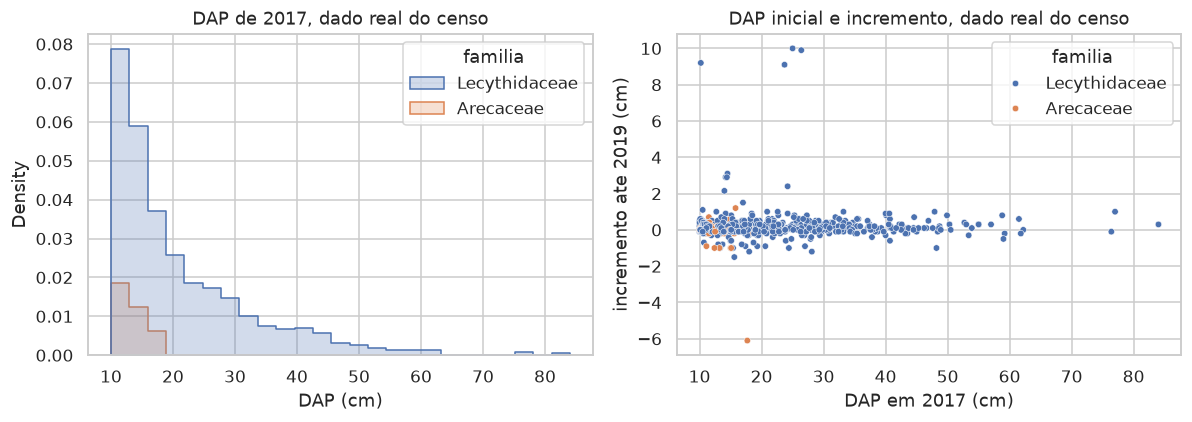

Dado real, nao sintetico: Cunha et al. 2021, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. Tratamento da parcela ausente no arquivo; nao foi imputado.
treino 534 teste 230 palmeiras no teste 25


In [2]:
import zipfile

aviso = (
    "Dado real, nao sintetico: Cunha et al. 2021, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. "
    "Contains data supplied by UK Centre for Ecology & Hydrology. "
    "Tratamento da parcela ausente no arquivo; nao foi imputado."
)
print(aviso)

arquivo = baixar(
    "https://data-package.ceh.ac.uk/data/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3.zip",
    PASTA_DADOS / "censo_amazonia_central.zip",
)
with zipfile.ZipFile(arquivo) as pacote:
    with pacote.open("data/tree_census.csv") as bruto:
        censo = pd.read_csv(bruto, sep=";", encoding="latin-1", na_values=["NA", ""])

censo["familia"] = censo["Family"].astype(str).str.strip()
censo["dap_2017"] = pd.to_numeric(censo["DBH_1"], errors="coerce")
censo["dap_2019"] = pd.to_numeric(censo["DBH_3"], errors="coerce")
base = censo.dropna(subset=["dap_2017", "dap_2019", "familia"]).copy()
base["incremento"] = base["dap_2019"] - base["dap_2017"]
foco = base[base["familia"].isin(["Arecaceae", "Lecythidaceae"])].copy()
foco["y"] = (foco["familia"] == "Arecaceae").astype(int)
print("arvores com os dois DAPs", len(base))
print(foco["familia"].value_counts())
print(aviso)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=foco, x="dap_2017", hue="familia", bins=25, element="step", stat="density", ax=eixos[0])
eixos[0].set_title("DAP de 2017, dado real do censo")
eixos[0].set_xlabel("DAP (cm)")
sns.scatterplot(data=foco, x="dap_2017", y="incremento", hue="familia", s=18, ax=eixos[1])
eixos[1].set_title("DAP inicial e incremento, dado real do censo")
eixos[1].set_xlabel("DAP em 2017 (cm)")
eixos[1].set_ylabel("incremento ate 2019 (cm)")
plt.tight_layout()
plt.show()
print(aviso)

from sklearn.model_selection import train_test_split

X = foco[["dap_2017", "incremento"]].to_numpy(float)
y = foco["y"].to_numpy()
X_tr, X_te, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
X_treino_p, X_teste_p, media, desvio = padronizar(X_tr, X_te)
print("treino", len(y_treino), "teste", len(y_teste), "palmeiras no teste", int(y_teste.sum()))


## 4) Implementação do zero

O modelo da figura e o mesmo da avaliacao: so estas duas medidas. Nao ha um "modelo completo" escondido.

Dado real, nao sintetico: censo de arvores em parcelas de adubacao na Amazonia Central, Cunha et al. 2021, NERC Environmental Information Data Centre, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. O CSV nao informa qual parcela recebeu qual adubo; esse rotulo nao e inventado.


Dado real, nao sintetico: Cunha et al. 2021, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. Tratamento da parcela ausente no arquivo; nao foi imputado.
perda 0.6931 -> 0.3048
pesos [dap_2017, incremento] [-1.54786121 -1.01450799] vies -2.7668178548831457


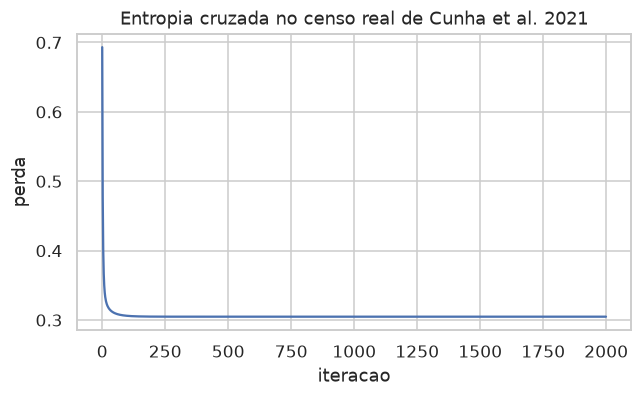

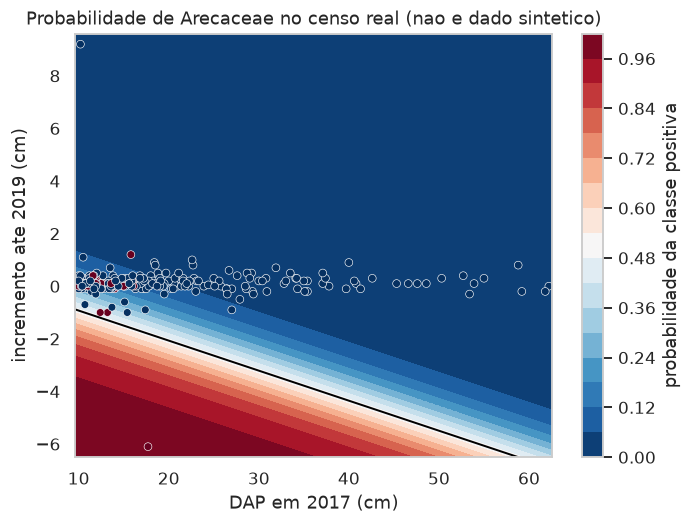

Dado real, nao sintetico: Cunha et al. 2021, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. Tratamento da parcela ausente no arquivo; nao foi imputado.


In [3]:
from mlalgos import LogisticRegression

print(aviso)
l2 = 1.0 / len(X_treino_p)
modelo = LogisticRegression(learning_rate=1.0, n_iterations=2000, l2=l2).fit(X_treino_p, y_treino)
print("perda", round(modelo.loss_history_[0], 4), "->", round(modelo.loss_history_[-1], 4))
print("pesos [dap_2017, incremento]", modelo.coef_, "vies", modelo.intercept_)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(modelo.loss_history_)
ax.set_xlabel("iteracao")
ax.set_ylabel("perda")
ax.set_title("Entropia cruzada no censo real de Cunha et al. 2021")
plt.show()
xx, yy = np.meshgrid(
    np.linspace(X_te[:, 0].min() - 0.4, X_te[:, 0].max() + 0.4, 220),
    np.linspace(X_te[:, 1].min() - 0.4, X_te[:, 1].max() + 0.4, 220),
)
grade = np.column_stack([xx.ravel(), yy.ravel()])
grade_p = (grade - media) / desvio
probabilidade = modelo.predict_proba(grade_p)[:, 1].reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7, 5))
mapa = ax.contourf(xx, yy, probabilidade, levels=16, cmap="RdBu_r")
ax.contour(xx, yy, probabilidade, levels=[0.5], colors="black", linewidths=1.3)
ax.scatter(X_te[:, 0], X_te[:, 1], c=y_teste, cmap="RdBu_r", edgecolor="white", linewidth=0.4, s=26)
fig.colorbar(mapa, ax=ax, label="probabilidade da classe positiva")
ax.set_xlabel('DAP em 2017 (cm)')
ax.set_ylabel('incremento ate 2019 (cm)')
ax.set_title('Probabilidade de Arecaceae no censo real (nao e dado sintetico)')
plt.show()

print(aviso)


## 5) Implementação com scikit-learn

Dado real, nao sintetico: censo de arvores em parcelas de adubacao na Amazonia Central, Cunha et al. 2021, NERC Environmental Information Data Centre, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. O CSV nao informa qual parcela recebeu qual adubo; esse rotulo nao e inventado.


In [4]:
from sklearn.linear_model import LogisticRegression as SkLogistic

print(aviso)
sk = SkLogistic(C=1.0, max_iter=800).fit(X_treino_p, y_treino)
print("acuracia nossa", float(modelo.score(X_teste_p, y_teste)))
print("acuracia sklearn", float(sk.score(X_teste_p, y_teste)))
print("concordancia", float(np.mean(modelo.predict(X_teste_p) == sk.predict(X_teste_p))))


Dado real, nao sintetico: Cunha et al. 2021, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. Tratamento da parcela ausente no arquivo; nao foi imputado.
acuracia nossa 0.8956521739130435
acuracia sklearn 0.8956521739130435
concordancia 1.0


## 6) Avaliação

O limiar padrao e 0,5. Com poucas palmeiras, ele pode prever lecitidacea o tempo todo e ainda assim ostentar acuracia alta. A ROC-AUC e o F1 contam a outra metade da historia. Em seguida o caderno escolhe, so no treino, o limiar de maior F1 e aplica esse limiar no teste. Os dois resultados sao do mesmo censo real.

Dado real, nao sintetico: censo de arvores em parcelas de adubacao na Amazonia Central, Cunha et al. 2021, NERC Environmental Information Data Centre, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. O CSV nao informa qual parcela recebeu qual adubo; esse rotulo nao e inventado.


acuracia 0.896 | baseline da classe majoritaria 0.891
precisao 1.000 | revocacao 0.040 | f1 0.077 | roc_auc 0.796
RESUMO_METRICAS {"modelo": "logistica_censo_amazonia_central", "acuracia": 0.8956521739130435, "precisao": 1.0, "revocacao": 0.04, "f1": 0.07692307692307693, "roc_auc": 0.7960975609756098, "baseline_majoritaria": 0.8913043478260869}


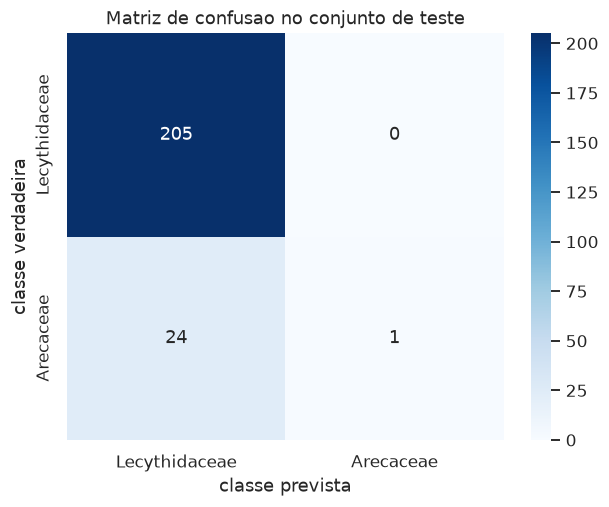

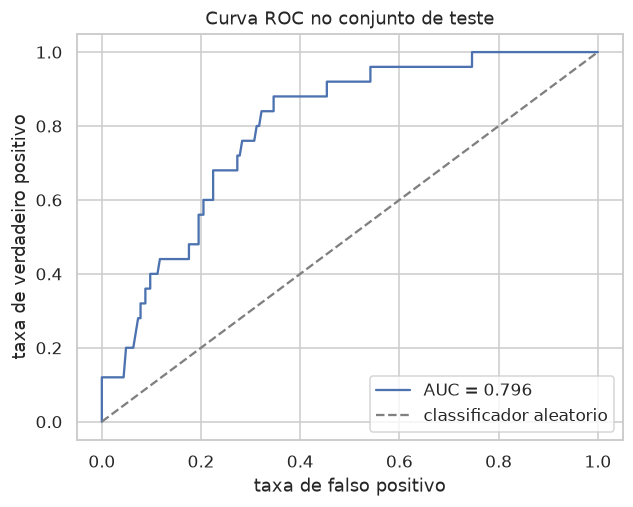

Dado real, nao sintetico: Cunha et al. 2021, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. Tratamento da parcela ausente no arquivo; nao foi imputado.
limiar escolhido no treino 0.1
f1 desse limiar no teste 0.324
Dado real, nao sintetico: Cunha et al. 2021, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. Tratamento da parcela ausente no arquivo; nao foi imputado.


In [5]:
from mlalgos.metrics import confusion_matrix, curva_roc, f1_score, precision_score, recall_score, roc_auc_score

y_previsto = modelo.predict(X_teste_p)
y_escore = modelo.predict_proba(X_teste_p)[:, 1]
acuracia = float(np.mean(y_previsto == y_teste))
precisao = precision_score(y_teste, y_previsto, pos_label=1)
revocacao = recall_score(y_teste, y_previsto, pos_label=1)
f1 = f1_score(y_teste, y_previsto, pos_label=1)
auc = roc_auc_score(y_teste, y_escore, pos_label=1)
baseline = float(max(np.mean(y_teste == 1), np.mean(y_teste == 0)))
print(f"acuracia {acuracia:.3f} | baseline da classe majoritaria {baseline:.3f}")
print(f"precisao {precisao:.3f} | revocacao {revocacao:.3f} | f1 {f1:.3f} | roc_auc {auc:.3f}")
print("RESUMO_METRICAS " + json.dumps({
    "modelo": 'logistica_censo_amazonia_central',
    "acuracia": acuracia,
    "precisao": precisao,
    "revocacao": revocacao,
    "f1": f1,
    "roc_auc": auc,
    "baseline_majoritaria": baseline,
}))

cm = confusion_matrix(y_teste, y_previsto, labels=[0, 1])
fig, ax = plt.subplots()
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=['Lecythidaceae', 'Arecaceae'], yticklabels=['Lecythidaceae', 'Arecaceae'], ax=ax,
)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe verdadeira")
ax.set_title("Matriz de confusao no conjunto de teste")
plt.show()

fpr, tpr, _ = curva_roc(y_teste, y_escore, pos_label=1)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="classificador aleatorio")
ax.set_xlabel("taxa de falso positivo")
ax.set_ylabel("taxa de verdadeiro positivo")
ax.set_title("Curva ROC no conjunto de teste")
ax.legend()
plt.show()

print(aviso)
from mlalgos.metrics import f1_score

escore_tr = modelo.predict_proba(X_treino_p)[:, 1]
candidatos = np.linspace(0.05, 0.95, 19)
f1s = [f1_score(y_treino, (escore_tr >= t).astype(int), pos_label=1) for t in candidatos]
limiar = float(candidatos[int(np.argmax(f1s))])
previsto_te = (modelo.predict_proba(X_teste_p)[:, 1] >= limiar).astype(int)
print("limiar escolhido no treino", round(limiar, 2))
print("f1 desse limiar no teste", round(f1_score(y_teste, previsto_te, pos_label=1), 3))
print(aviso)


## 7) Desafios

1. Repita com `Sapotaceae` contra `Burseraceae`, as duas familias abundantes, e compare a AUC com a deste par. O diametro separa todo mundo, ou so este contraste de porte?
2. Tire o incremento e deixe so o DAP. Quanto da AUC era tamanho, e quanto era crescimento?
3. O arquivo tem blocos `B1` a `B4`. Nao rotule bloco como "adubado" sem uma tabela de tratamento. Escreva de onde essa tabela teria de vir para a pergunta experimental ficar honesta.

Dado real, nao sintetico: censo de arvores em parcelas de adubacao na Amazonia Central, Cunha et al. 2021, NERC Environmental Information Data Centre, DOI 10.5285/c2587e20-ba4a-4444-8ce9-ccdec15b0aa3. Contains data supplied by UK Centre for Ecology & Hydrology. O CSV nao informa qual parcela recebeu qual adubo; esse rotulo nao e inventado.
